# Heart Disease Prediction using Classification Models
**Course:** Predictive Analytics (CSE3141), Manipal University Jaipur  
**Name:** Aditya Singh | **Reg. No.:** 2427030054

## Problem statement
Predict whether a patient has heart disease from clinical measurements (age, blood pressure, cholesterol, ECG results, etc.).

## Dataset
UCI Heart Disease (Cleveland subset): https://archive.ics.uci.edu/dataset/45/heart+disease  
303 patients, 13 features. The original target `num` (0-4) is converted to binary: 0 = no disease, 1 = disease.

## Machine learning approach
1. Data cleaning: missing values and outliers (IQR)
2. EDA: summary statistics, z-scores, histograms, box plots, heatmap, scatter plots
3. Feature engineering and feature selection
4. Models: Logistic Regression, LDA, QDA (supervised classification)
5. Validation: stratified train-test split and 5-fold cross-validation
6. Metrics: Accuracy, Precision, Recall, F1-score, AUC-ROC
7. Hyperparameter tuning: Grid Search
8. Overfitting / underfitting check

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("../reports/figures", exist_ok=True)
os.makedirs("../data", exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"../reports/figures/{name}.png", dpi=150)

## 1. Load the data
The notebook downloads the dataset from UCI using the `ucimlrepo` package and saves a local copy to `data/heart_disease.csv`. If you are offline, put the CSV in `data/` (13 feature columns + a binary `target` column) and it will be read from there.

In [2]:
DATA_PATH = "../data/heart_disease.csv"
try:
    from ucimlrepo import fetch_ucirepo
    heart = fetch_ucirepo(id=45)                      # UCI Heart Disease
    df = heart.data.features.copy()
    df["target"] = (heart.data.targets["num"] > 0).astype(int)   # 0 = healthy, 1 = disease
    df.to_csv(DATA_PATH, index=False)
    print("Downloaded from UCI and saved to", DATA_PATH)
except Exception as e:
    print("Could not download (", type(e).__name__, "), reading local CSV instead")
    df = pd.read_csv(DATA_PATH)

print(df.shape)
df.head()

Downloaded from UCI and saved to ../data/heart_disease.csv
(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


### Feature description
| Feature | Meaning |
|---|---|
| age | Age in years |
| sex | 1 = male, 0 = female |
| cp | Chest pain type (1-4) |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl (1 = yes) |
| restecg | Resting ECG result (0-2) |
| thalach | Maximum heart rate achieved |
| exang | Exercise-induced angina (1 = yes) |
| oldpeak | ST depression induced by exercise |
| slope | Slope of peak exercise ST segment |
| ca | Number of major vessels coloured by fluoroscopy (0-3) |
| thal | Thalassemia result (3 = normal, 6 = fixed defect, 7 = reversible defect) |
| target | 1 = heart disease, 0 = no disease |

## 2. Data cleaning

In [3]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
df.info()

Missing values per column:
ca      4
thal    2
dtype: int64

Duplicate rows: 0
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


**Missing values:** `ca` and `thal` have a few missing entries. They are imputed *inside the modelling pipeline* (median for numeric, most frequent for categorical) so that the imputation is learned only from the training data (no data leakage). For EDA only, a filled copy is used below.

**Outliers:** detected with the IQR rule and visualised with box plots.

In [4]:
df_eda = df.copy()
df_eda["ca"] = df_eda["ca"].fillna(df_eda["ca"].median())
df_eda["thal"] = df_eda["thal"].fillna(df_eda["thal"].mode()[0])

num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
rows = []
for c in num_cols:
    q1, q3 = df_eda[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append([c, lo, hi, ((df_eda[c] < lo) | (df_eda[c] > hi)).sum()])
outlier_table = pd.DataFrame(rows, columns=["feature", "lower_bound", "upper_bound", "n_outliers"])
outlier_table

,feature,lower_bound,upper_bound,n_outliers
0,age,28.50,80.50,0
1,trestbps,90.00,170.00,9
2,chol,115.00,371.00,5
3,thalach,84.75,214.75,1
4,oldpeak,-2.40,4.00,5


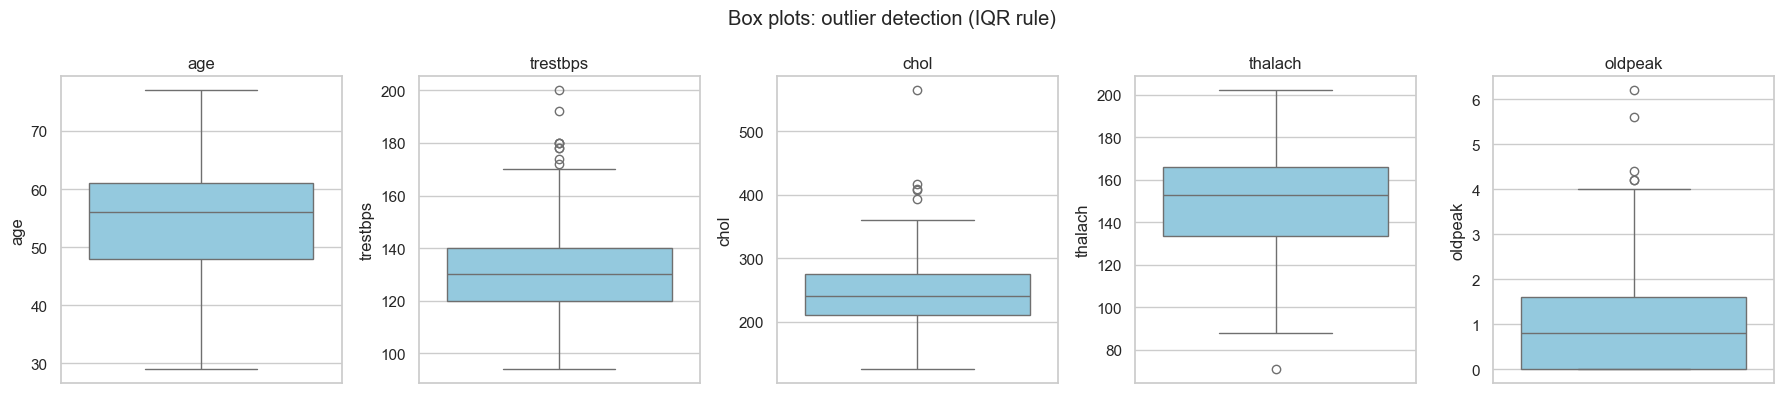

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df_eda[c], ax=ax, color="skyblue")
    ax.set_title(c)
fig.suptitle("Box plots: outlier detection (IQR rule)")
save_fig("01_boxplots")
plt.show()

The outliers are few and medically plausible (e.g. high cholesterol), so they are **kept** rather than removed. Using standardisation and regularised models limits their influence. (Alternative: cap them at the IQR bounds.)

## 3. Exploratory Data Analysis (EDA)

In [6]:
# Mean, median, mode, variance, standard deviation
summary = pd.DataFrame({
    "mean": df_eda[num_cols].mean(),
    "median": df_eda[num_cols].median(),
    "mode": df_eda[num_cols].mode().iloc[0],
    "variance": df_eda[num_cols].var(),
    "std": df_eda[num_cols].std(),
})
summary.round(2)

,mean,median,mode,variance,std
age,54.44,56.0,58.0,81.70,9.04
trestbps,131.69,130.0,120.0,309.75,17.60
chol,246.69,241.0,197.0,2680.85,51.78
thalach,149.61,153.0,162.0,523.27,22.88
oldpeak,1.04,0.8,0.0,1.35,1.16


In [7]:
# Z-scores: how many values lie more than 3 standard deviations from the mean
z = np.abs(stats.zscore(df_eda[num_cols]))
print("Values with |z| > 3 per column:")
print(pd.Series((z > 3).sum(axis=0), index=num_cols))

Values with |z| > 3 per column:
age         0
trestbps    2
chol        4
thalach     1
oldpeak     2
dtype: int64


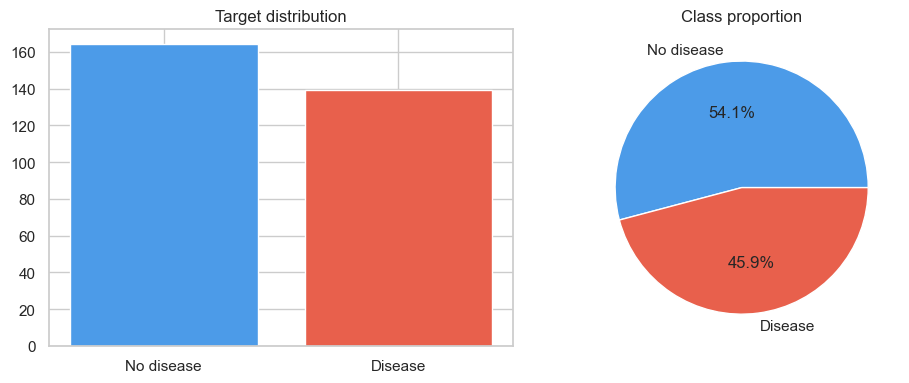

In [8]:
# Class balance (pie + bar)
counts = df["target"].value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(["No disease", "Disease"], counts.values, color=["#4c9be8", "#e8604c"])
ax[0].set_title("Target distribution")
ax[1].pie(counts.values, labels=["No disease", "Disease"], autopct="%1.1f%%", colors=["#4c9be8", "#e8604c"])
ax[1].set_title("Class proportion")
save_fig("02_target_distribution")
plt.show()

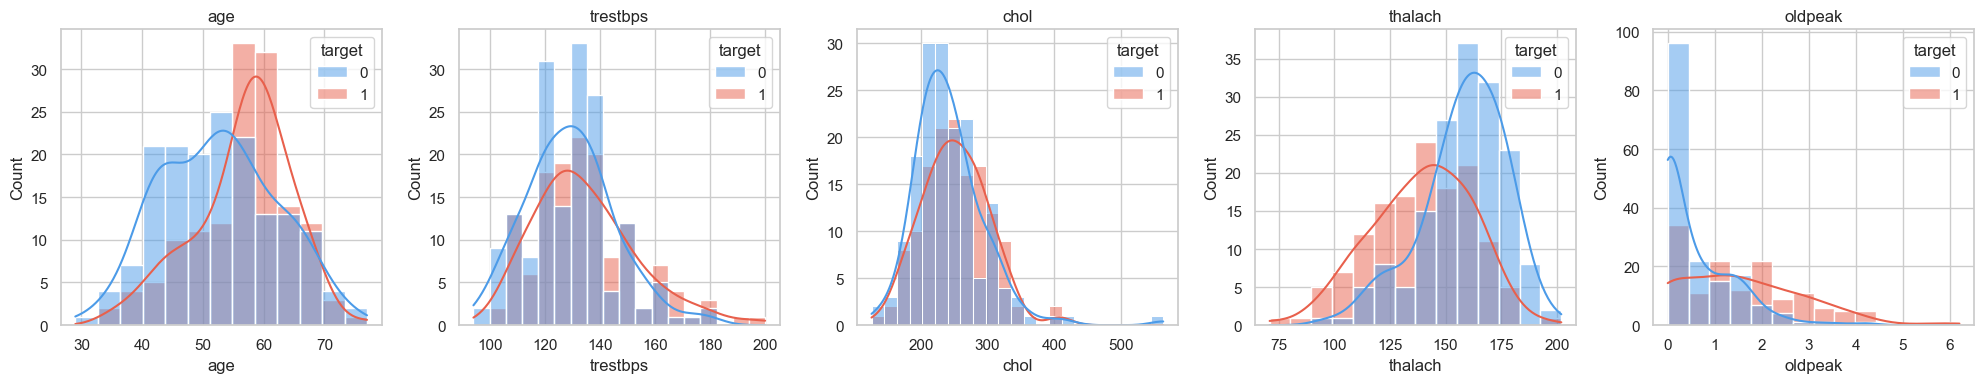

In [9]:
# Histograms of numeric features split by target
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, c in zip(axes, num_cols):
    sns.histplot(data=df_eda, x=c, hue="target", kde=True, ax=ax, palette=["#4c9be8", "#e8604c"])
    ax.set_title(c)
save_fig("03_histograms")
plt.show()

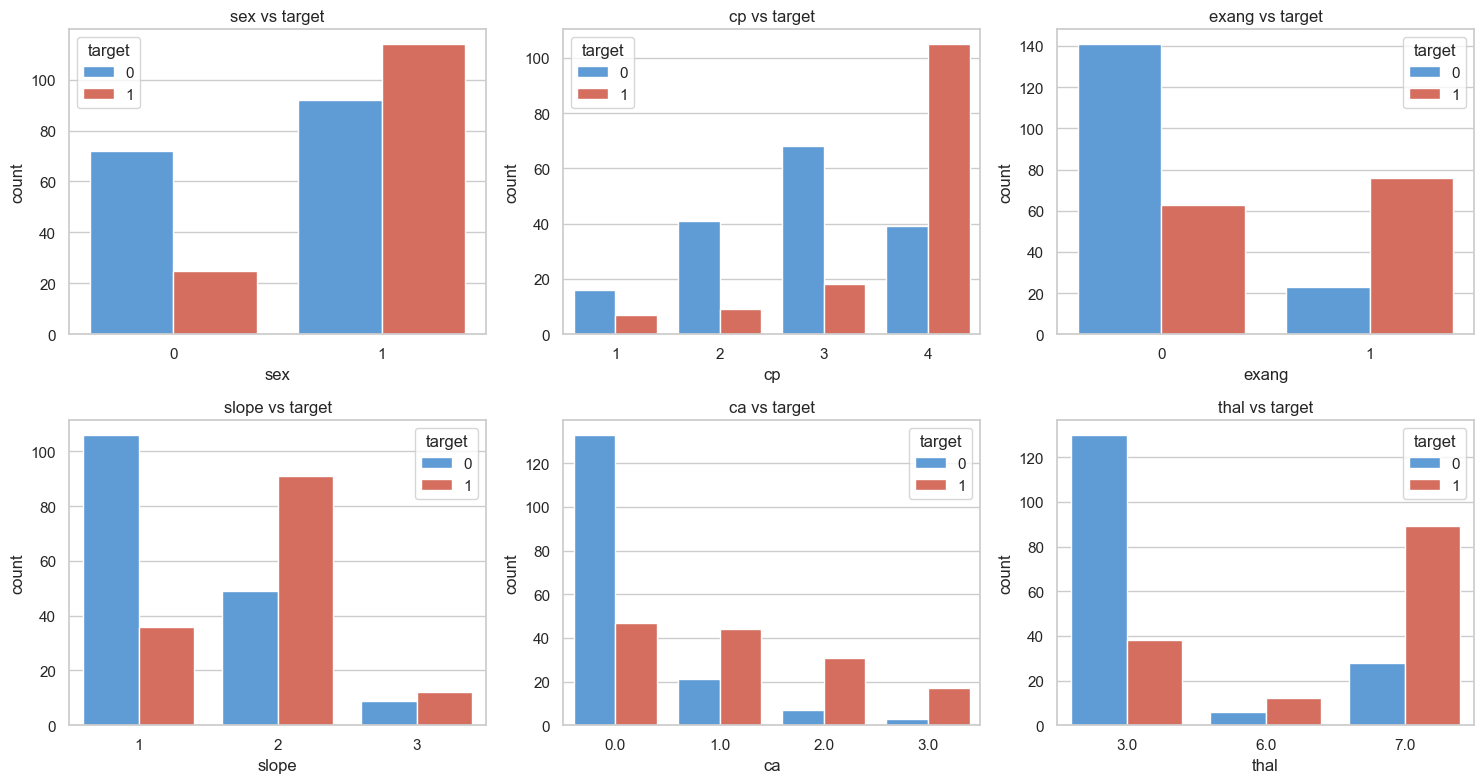

In [10]:
# Bar charts of categorical features vs target
cat_plot = ["sex", "cp", "exang", "slope", "ca", "thal"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cat_plot):
    sns.countplot(data=df_eda, x=c, hue="target", ax=ax, palette=["#4c9be8", "#e8604c"])
    ax.set_title(f"{c} vs target")
save_fig("04_categorical_vs_target")
plt.show()

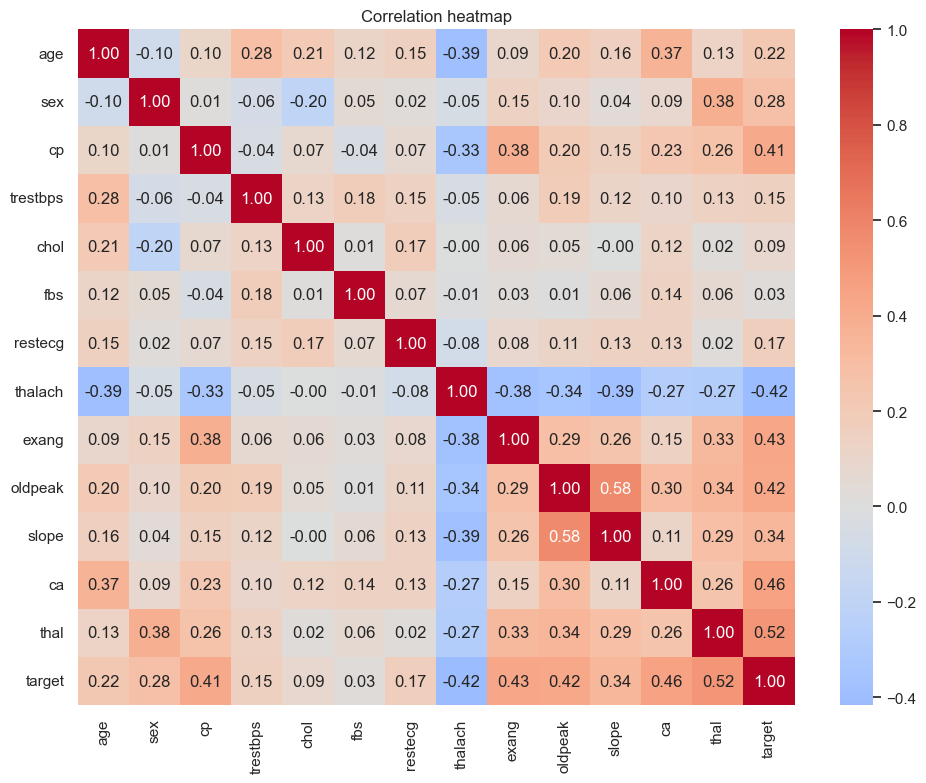

In [11]:
# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df_eda.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
save_fig("05_heatmap")
plt.show()

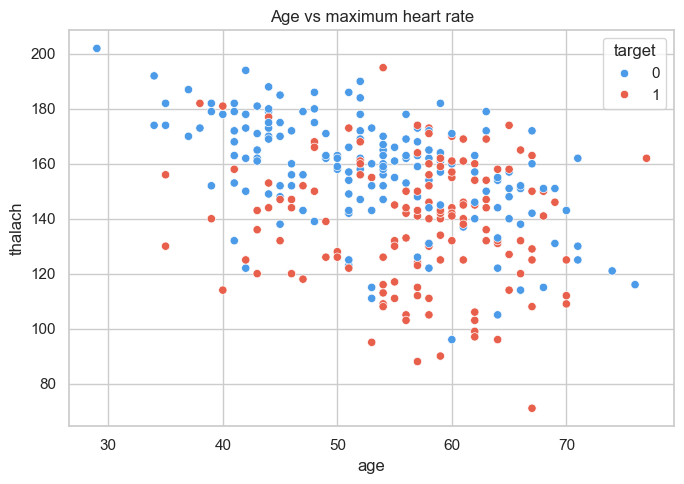

In [12]:
# Scatter plot: age vs max heart rate, coloured by disease status
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_eda, x="age", y="thalach", hue="target", palette=["#4c9be8", "#e8604c"])
plt.title("Age vs maximum heart rate")
save_fig("06_scatter_age_thalach")
plt.show()

**EDA observations** (check these against your own plots before writing them in your report):
- The classes are roughly balanced, so accuracy is meaningful, but F1 and AUC are still reported.
- Patients with disease tend to have a lower maximum heart rate (`thalach`) and higher `oldpeak`.
- `cp`, `exang`, `ca` and `thal` show clear differences between the two classes.

## 4. Feature engineering and feature selection
**Engineered features** (deterministic, so no leakage):
- `hr_ratio` = thalach / (220 - age): achieved heart rate as a fraction of the age-predicted maximum
- `high_chol` = 1 if chol > 240 mg/dl (medical "high" threshold)
- `high_bp` = 1 if resting blood pressure >= 140 mm Hg (hypertension threshold)

**Preprocessing:** numeric columns are imputed (median) and standardised; categorical columns are imputed (most frequent) and one-hot encoded.

In [13]:
def add_features(d):
    d = d.copy()
    d["hr_ratio"] = d["thalach"] / (220 - d["age"])
    d["high_chol"] = (d["chol"] > 240).astype(int)
    d["high_bp"] = (d["trestbps"] >= 140).astype(int)
    return d

df_fe = add_features(df)
X = df_fe.drop(columns="target")
y = df_fe["target"]

numeric_features = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca", "hr_ratio"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal", "high_chol", "high_bp"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])

# Stratified train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train class ratio:", y_train.mean().round(3), "| Test class ratio:", y_test.mean().round(3))

Train: (242, 16) Test: (61, 16)
Train class ratio: 0.459 | Test class ratio: 0.459


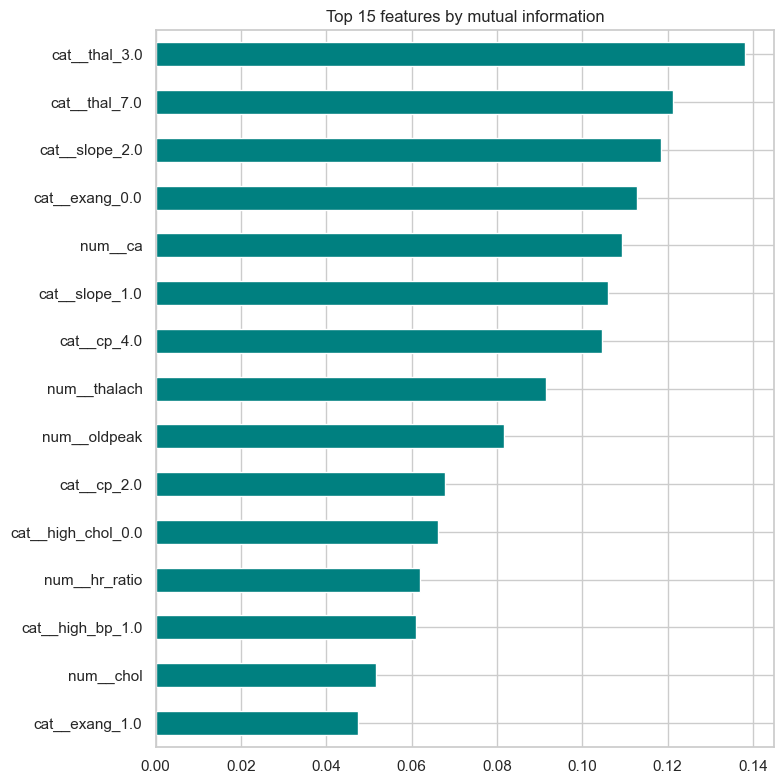

cat__thal_3.0     0.138044
cat__thal_7.0     0.121165
cat__slope_2.0    0.118525
cat__exang_0.0    0.112938
num__ca           0.109200
cat__slope_1.0    0.106074
cat__cp_4.0       0.104597
num__thalach      0.091476
num__oldpeak      0.081680
cat__cp_2.0       0.067844
dtype: float64

In [14]:
# Feature selection: mutual information scores on the training set
pre_fit = preprocess.fit(X_train)
Xt = pre_fit.transform(X_train)
Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
feat_names = pre_fit.get_feature_names_out()

mi = pd.Series(mutual_info_classif(Xt, y_train, random_state=RANDOM_STATE), index=feat_names).sort_values(ascending=False)
plt.figure(figsize=(8, 8))
mi.head(15).sort_values().plot.barh(color="teal")
plt.title("Top 15 features by mutual information")
save_fig("07_feature_importance_mi")
plt.show()
mi.head(10)

Feature selection is also included **inside the pipeline** with `SelectKBest`; the number of features `k` is tuned by Grid Search in section 7.

## 5. Baseline models with cross-validation
Three supervised classifiers from the syllabus:
- **Logistic Regression**: models log-odds of disease as a linear function of the features
- **LDA** (Linear Discriminant Analysis): assumes each class is Gaussian with a shared covariance matrix
- **QDA** (Quadratic Discriminant Analysis): Gaussian classes with separate covariance matrices (more flexible, more prone to overfitting)

Each is evaluated with stratified 5-fold cross-validation on the training set only.

In [15]:
def make_pipe(clf):
    return Pipeline([("pre", preprocess), ("select", SelectKBest(f_classif, k="all")), ("clf", clf)])

models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "LDA": make_pipe(LinearDiscriminantAnalysis()),
    "QDA": make_pipe(QuadraticDiscriminantAnalysis(reg_param=0.5)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
baseline_rows = []
for name, pipe in models.items():
    acc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    baseline_rows.append([name, acc.mean(), acc.std(), f1.mean(), auc.mean()])

baseline = pd.DataFrame(baseline_rows, columns=["Model", "CV Accuracy", "CV Acc Std", "CV F1", "CV AUC"]).round(3)
baseline

,Model,CV Accuracy,CV Acc Std,CV F1,CV AUC
0,Logistic Regression,0.826,0.022,0.802,0.900
1,LDA,0.818,0.024,0.794,0.887
2,QDA,0.818,0.016,0.786,0.882


## 6. Evaluation metrics
- **Accuracy**: fraction of correct predictions
- **Precision**: of the patients predicted as diseased, how many really are
- **Recall (sensitivity)**: of the truly diseased patients, how many are found (very important in medicine: a missed case is costly)
- **F1-score**: harmonic mean of precision and recall
- **AUC-ROC**: ability to rank diseased patients above healthy ones across all thresholds

## 7. Hyperparameter tuning (Grid Search)
Grid Search with 5-fold CV, optimising **AUC-ROC**.

In [16]:
param_grids = {
    "Logistic Regression": {
        "select__k": [8, 12, 16, "all"],
        "clf__C": [0.01, 0.1, 1, 10, 100],
        "clf__penalty": ["l2"],
    },
    "LDA": {
        "select__k": [8, 12, 16, "all"],
        "clf__solver": ["lsqr"],
        "clf__shrinkage": [None, 0.1, 0.3, 0.5, "auto"],
    },
    "QDA": {
        "select__k": [6, 8, 12],
        "clf__reg_param": [0.0, 0.1, 0.3, 0.5, 0.7, 0.9],
    },
}

best_models = {}
for name, pipe in models.items():
    gs = GridSearchCV(pipe, param_grids[name], cv=cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    print(f"{name}: best CV AUC = {gs.best_score_:.3f} | best params = {gs.best_params_}")

Logistic Regression: best CV AUC = 0.910 | best params = {'clf__C': 10, 'clf__penalty': 'l2', 'select__k': 12}
LDA: best CV AUC = 0.913 | best params = {'clf__shrinkage': 0.3, 'clf__solver': 'lsqr', 'select__k': 12}
QDA: best CV AUC = 0.898 | best params = {'clf__reg_param': 0.1, 'select__k': 12}


## 8. Final evaluation on the held-out test set

In [17]:
results = []
probas = {}
for name, model in best_models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    probas[name] = proba
    results.append([name,
                    accuracy_score(y_test, pred), precision_score(y_test, pred),
                    recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, proba)])

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]).round(3)
results_df.to_csv("../reports/results.csv", index=False)
results_df

,Model,Accuracy,Precision,Recall,F1,AUC-ROC
0,Logistic Regression,0.852,0.806,0.893,0.847,0.942
1,LDA,0.902,0.867,0.929,0.897,0.952
2,QDA,0.902,0.867,0.929,0.897,0.940


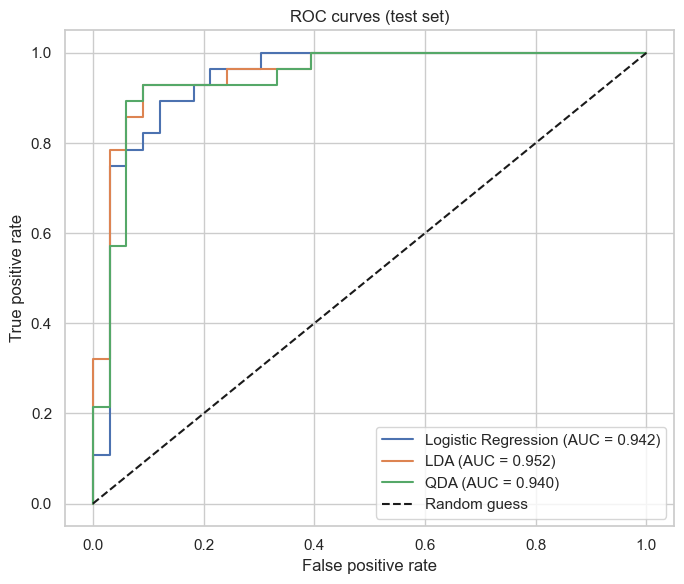

In [18]:
# ROC curves
plt.figure(figsize=(7, 6))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves (test set)"); plt.legend()
save_fig("08_roc_curves")
plt.show()

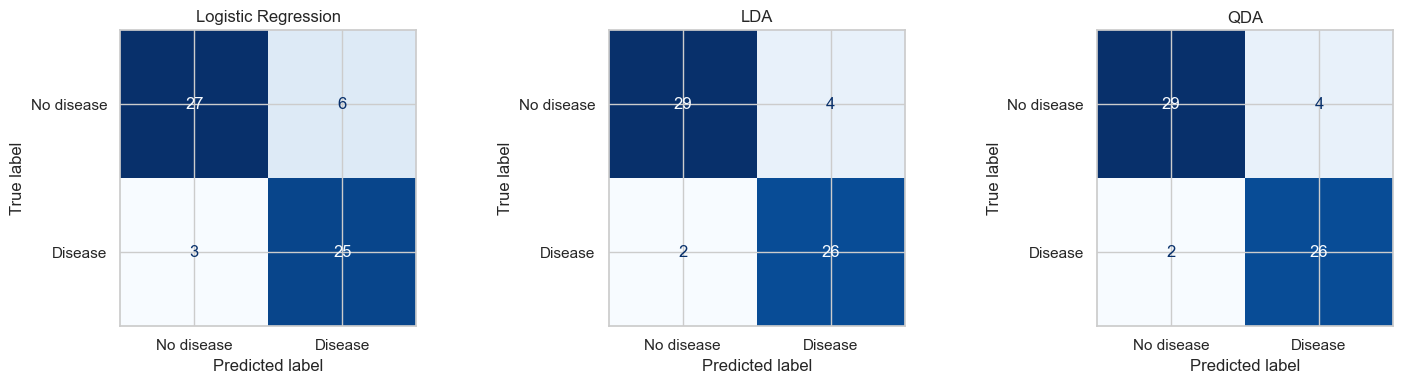

In [19]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap="Blues",
                                          display_labels=["No disease", "Disease"], colorbar=False)
    ax.set_title(name)
save_fig("09_confusion_matrices")
plt.show()

## 9. Overfitting and underfitting check
- Compare **train vs test** scores: a large gap means overfitting; low scores on both mean underfitting.
- **Learning curves** show how performance changes with training-set size.

In [20]:
gap = []
for name, model in best_models.items():
    tr = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
    te = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    gap.append([name, tr, te, tr - te])
pd.DataFrame(gap, columns=["Model", "Train AUC", "Test AUC", "Gap"]).round(3)

,Model,Train AUC,Test AUC,Gap
0,Logistic Regression,0.923,0.942,-0.019
1,LDA,0.915,0.952,-0.037
2,QDA,0.922,0.940,-0.019


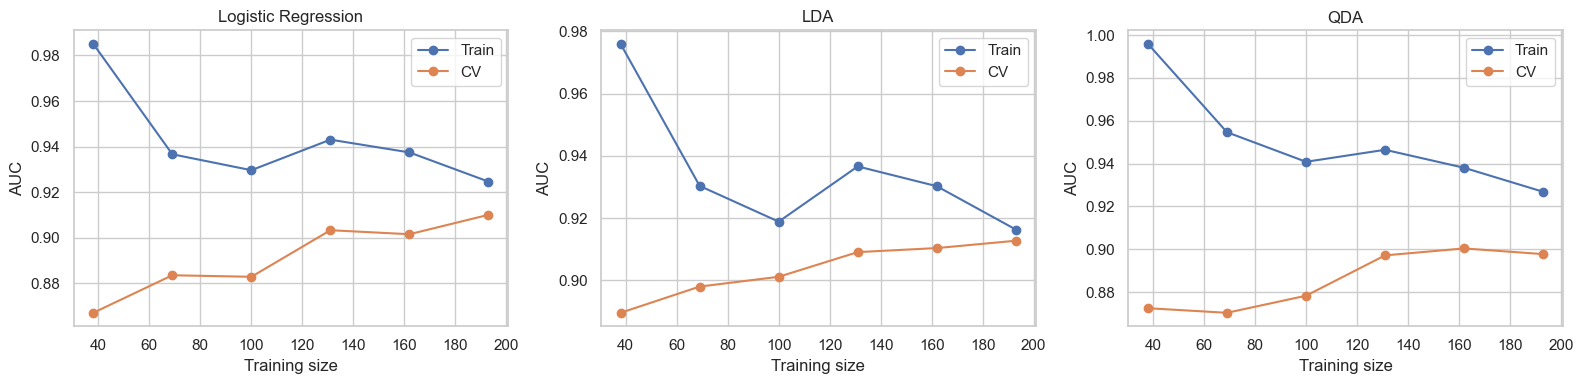

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, model) in zip(axes, best_models.items()):
    sizes, tr_s, va_s = learning_curve(model, X_train, y_train, cv=cv, scoring="roc_auc",
                                       train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1)
    ax.plot(sizes, tr_s.mean(axis=1), "o-", label="Train")
    ax.plot(sizes, va_s.mean(axis=1), "o-", label="CV")
    ax.set_title(name); ax.set_xlabel("Training size"); ax.set_ylabel("AUC"); ax.legend()
save_fig("10_learning_curves")
plt.show()

## 10. Interpreting the Logistic Regression model

           feature  coefficient  odds_ratio
11   cat__thal_7.0        1.452       4.270
4     cat__sex_1.0        1.384       3.990
5      cat__cp_4.0        1.372       3.942
2          num__ca        1.142       3.132
8   cat__slope_1.0       -0.619       0.538
9   cat__slope_2.0        0.578       1.783
0     num__thalach       -0.400       0.670
6   cat__exang_0.0       -0.298       0.742
7   cat__exang_1.0        0.289       1.335
3    num__hr_ratio        0.184       1.203


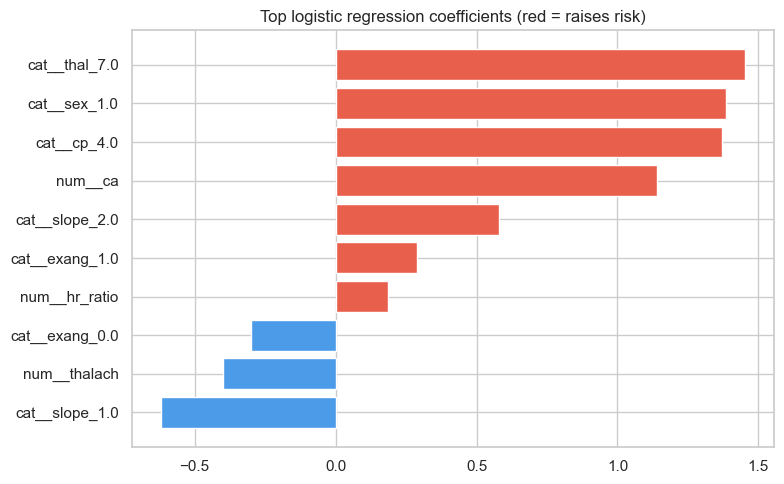

In [22]:
lr = best_models["Logistic Regression"]
selected = lr.named_steps["select"].get_support()
names = np.array(lr.named_steps["pre"].get_feature_names_out())[selected]
coefs = lr.named_steps["clf"].coef_[0]

coef_df = pd.DataFrame({"feature": names, "coefficient": coefs, "odds_ratio": np.exp(coefs)})
coef_df = coef_df.reindex(coef_df["coefficient"].abs().sort_values(ascending=False).index)
display(coef_df.head(10).round(3)) if "display" in globals() else print(coef_df.head(10).round(3))

top = coef_df.head(10).sort_values("coefficient")
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["coefficient"], color=np.where(top["coefficient"] > 0, "#e8604c", "#4c9be8"))
plt.title("Top logistic regression coefficients (red = raises risk)")
save_fig("11_lr_coefficients")
plt.show()

## 11. Conclusion
LDA performed best on the held-out test set (accuracy 0.902, F1 0.897, AUC-ROC 0.952), slightly ahead of Logistic Regression and QDA. All three models achieved high recall (≥ 0.89), which is important in a medical setting where missing a diseased patient is costly. Because the test set contains only 61 patients, the differences between models are small and may not be statistically significant. Limitations: the dataset is small (303 patients) and comes from a single hospital, so results may not generalise. The model should support doctors, not replace them.